### **1. Import libraries and configure paths**

In [2]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    import plotly.express as px
    import plotly.graph_objects as go
    PLOTLY_AVAILABLE = True
except ImportError:
    PLOTLY_AVAILABLE = False

# Google Colab paths; change these if you are running locally.
DATA_FILE = Path("/content/sales_integrated.csv")
FORECAST_FILE = Path("/content/future_sales_forecast.csv")
OUTPUT_DIR = Path("/content/week12_final_project")
TABLE_DIR = OUTPUT_DIR / "tables"
FIGURE_DIR = OUTPUT_DIR / "figures"

for folder in [OUTPUT_DIR, TABLE_DIR, FIGURE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {DATA_FILE}. Upload sales_integrated.csv or update DATA_FILE."
    )

print("Output folder:", OUTPUT_DIR)

Output folder: /content/week12_final_project


### **2. Load and inspect integrated sales data**

In [3]:
data = pd.read_csv(DATA_FILE)
print("Dataset shape:", data.shape)
print("Columns:", data.columns.tolist())
display(data.head())
display(data.info())

Dataset shape: (130402, 55)
Columns: ['so_id', 'line_number', 'product_id', 'quantity', 'unit_price', 'gst_rate', 'line_total', 'gst_amount', 'line_grand_total', 'customer_id', 'branch_id', 'order_date', 'delivery_date', 'order_status', 'payment_terms', 'total_order_value', 'total_gst_amount', 'grand_total', 'sales_channel', 'product_name', 'category', 'machine_type', 'brand', 'model_compatibility', 'unit_cost', 'unit_price_product', 'margin_percentage', 'gst_rate_product', 'weight_kg', 'dimensions_cm', 'material_type', 'warranty_months', 'reorder_level', 'safety_stock', 'max_stock_level', 'lead_time_days', 'criticality_level', 'usage_frequency', 'uom', 'last_purchase_price', 'last_purchase_date', 'customer_type', 'industry_segment', 'city', 'state', 'pincode', 'region', 'branch_id_customer', 'credit_limit', 'current_balance', 'payment_terms_customer', 'customer_since', 'last_purchase_date_customer', 'total_purchase_value', 'customer_rating']


,so_id,line_number,product_id,quantity,unit_price,gst_rate,line_total,gst_amount,line_grand_total,customer_id,...,pincode,region,branch_id_customer,credit_limit,current_balance,payment_terms_customer,customer_since,last_purchase_date_customer,total_purchase_value,customer_rating
0,SO-990591,1,P018,19,11300,28,214700,60116.0,274816.0,C0070,...,784913,West,AHM001,549454,84153,Net 30,2022-11-10,2024-12-04,4644233,3
1,SO-990591,2,P026,2,310,18,620,111.6,731.6,C0070,...,784913,West,AHM001,549454,84153,Net 30,2022-11-10,2024-12-04,4644233,3
2,SO-990591,3,P026,3,310,18,930,167.4,1097.4,C0070,...,784913,West,AHM001,549454,84153,Net 30,2022-11-10,2024-12-04,4644233,3
3,SO-990591,4,P013,9,1450,18,13050,2349.0,15399.0,C0070,...,784913,West,AHM001,549454,84153,Net 30,2022-11-10,2024-12-04,4644233,3
4,SO-990591,5,P004,3,39800,28,119400,33432.0,152832.0,C0070,...,784913,West,AHM001,549454,84153,Net 30,2022-11-10,2024-12-04,4644233,3


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 130402 entries, 0 to 130401
Data columns (total 55 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   so_id                        130402 non-null  object 
 1   line_number                  130402 non-null  int64  
 2   product_id                   130402 non-null  object 
 3   quantity                     130402 non-null  int64  
 4   unit_price                   130402 non-null  int64  
 5   gst_rate                     130402 non-null  int64  
 6   line_total                   130402 non-null  int64  
 7   gst_amount                   130402 non-null  float64
 8   line_grand_total             130402 non-null  float64
 9   customer_id                  130402 non-null  object 
 10  branch_id                    130402 non-null  object 
 11  order_date                   130402 non-null  object 
 12  delivery_date                130402 non-null  object 
 13 

None

### **3. Data preparation and quality checks**

In [4]:
required_columns = ["so_id", "product_id", "quantity", "line_total", "customer_id", "branch_id", "order_date"]
missing_required = [c for c in required_columns if c not in data.columns]
if missing_required:
    raise ValueError(f"Required columns are missing: {missing_required}")

# Parse dates and coerce analytical numeric fields.
data["order_date"] = pd.to_datetime(data["order_date"], errors="coerce")
for col in ["quantity", "line_total", "unit_cost", "unit_price", "total_order_value", "gst_amount", "grand_total"]:
    if col in data.columns:
        data[col] = pd.to_numeric(data[col], errors="coerce")

# Retain records with the core fields needed for sales analysis.
rows_before = len(data)
data = data.dropna(subset=["so_id", "product_id", "quantity", "line_total", "order_date"]).copy()
rows_after = len(data)

# Remove negative or zero sales quantities/revenue from the main sales analysis.
# If returns/credit notes are explicitly represented in the source, analyse them separately.
data = data[(data["quantity"] > 0) & (data["line_total"] >= 0)].copy()

quality_summary = pd.DataFrame({
    "Metric": [
        "Rows before required-field cleaning", "Rows after required-field cleaning",
        "Rows removed by required-field cleaning", "Rows after positive-quantity filter",
        "Duplicate rows", "Missing order dates", "Unique orders", "Unique products",
        "Unique customers", "Unique branches"
    ],
    "Value": [
        rows_before, rows_after, rows_before - rows_after, len(data),
        int(data.duplicated().sum()), int(data["order_date"].isna().sum()),
        data["so_id"].nunique(), data["product_id"].nunique(),
        data["customer_id"].nunique(), data["branch_id"].nunique()
    ]
})
display(quality_summary)
quality_summary.to_csv(TABLE_DIR / "data_quality_summary.csv", index=False)
print("Analysis period:", data["order_date"].min(), "to", data["order_date"].max())

,Metric,Value
0,Rows before required-field cleaning,130402
1,Rows after required-field cleaning,130402
2,Rows removed by required-field cleaning,0
3,Rows after positive-quantity filter,130402
4,Duplicate rows,0
5,Missing order dates,0
6,Unique orders,20000
7,Unique products,30
8,Unique customers,500
9,Unique branches,6


Analysis period: 2019-01-01 00:00:00 to 2024-12-31 00:00:00


### **4. Executive KPIs**

In [5]:
total_revenue = data["line_total"].sum()
total_orders = data["so_id"].nunique()
total_units = data["quantity"].sum()
total_products = data["product_id"].nunique()
total_customers = data["customer_id"].nunique()
total_branches = data["branch_id"].nunique()
average_order_value = total_revenue / total_orders if total_orders else np.nan

executive_kpis = pd.DataFrame({
    "KPI": ["Total Revenue", "Total Orders", "Total Units Sold", "Total Products",
            "Total Customers", "Total Branches", "Average Order Value"],
    "Value": [total_revenue, total_orders, total_units, total_products,
              total_customers, total_branches, average_order_value]
})
display(executive_kpis)
executive_kpis.to_csv(TABLE_DIR / "executive_kpis.csv", index=False)

,KPI,Value
0,Total Revenue,2.544739e+10
1,Total Orders,2.000000e+04
2,Total Units Sold,1.368534e+06
3,Total Products,3.000000e+01
4,Total Customers,5.000000e+02
5,Total Branches,6.000000e+00
6,Average Order Value,1.272370e+06


### **5. Monthly sales trends and growth**

,order_date,revenue,units,orders,customers,revenue_growth_pct,units_growth_pct
60,2024-01-31,374371710,19921,305,231,10.433644,7.056105
61,2024-02-29,340878920,18443,260,213,-8.946400,-7.419306
62,2024-03-31,333840930,19151,282,212,-2.064660,3.838855
63,2024-04-30,318555000,16983,263,211,-4.578806,-11.320558
64,2024-05-31,326434300,17714,243,188,2.473450,4.304304
65,2024-06-30,351105300,19269,274,211,7.557723,8.778367
66,2024-07-31,340990310,18594,279,211,-2.880899,-3.503036
67,2024-08-31,337495540,19486,288,216,-1.024888,4.797246
68,2024-09-30,378860380,19800,297,217,12.256411,1.611413
69,2024-10-31,391009730,19525,283,218,3.206815,-1.388889


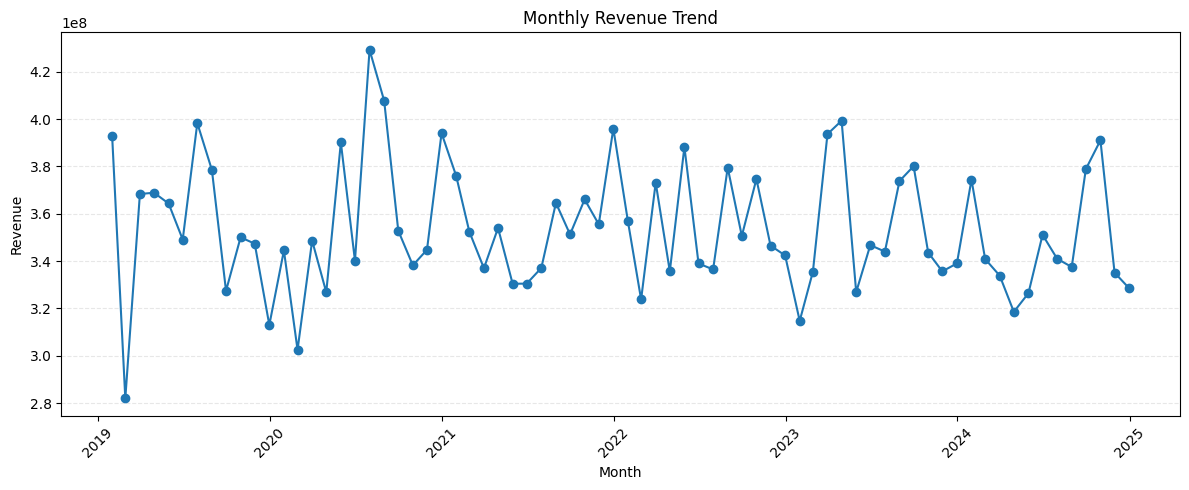

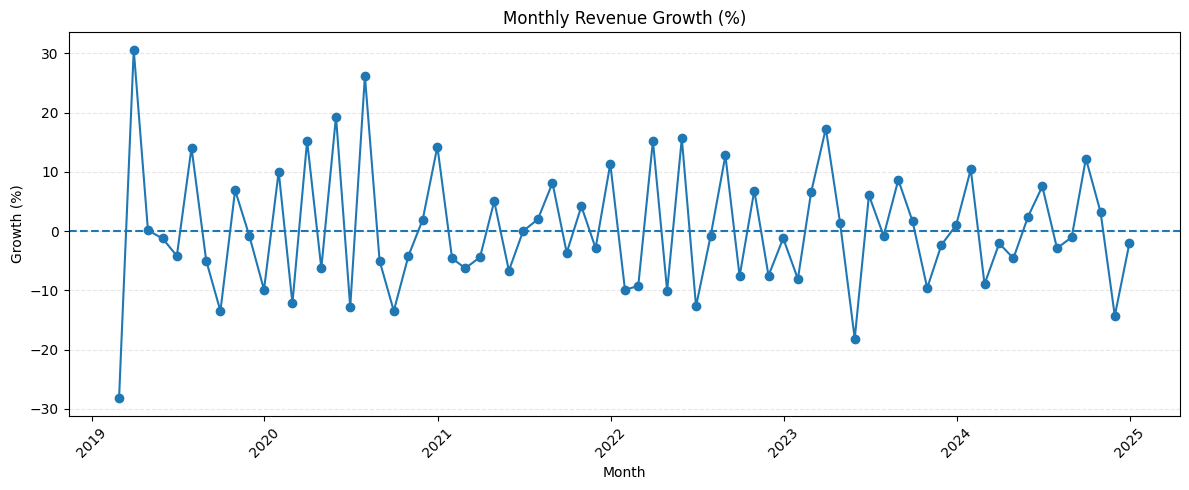

In [6]:
monthly_sales = (
    data.groupby(pd.Grouper(key="order_date", freq="ME"))
        .agg(revenue=("line_total", "sum"), units=("quantity", "sum"),
             orders=("so_id", "nunique"), customers=("customer_id", "nunique"))
        .reset_index()
)
monthly_sales["revenue_growth_pct"] = monthly_sales["revenue"].pct_change() * 100
monthly_sales["units_growth_pct"] = monthly_sales["units"].pct_change() * 100
display(monthly_sales.tail(12))
monthly_sales.to_csv(TABLE_DIR / "monthly_sales.csv", index=False)

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["order_date"], monthly_sales["revenue"], marker="o")
plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "monthly_revenue_trend.png", dpi=150)
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(monthly_sales["order_date"], monthly_sales["revenue_growth_pct"], marker="o")
plt.axhline(0, linestyle="--")
plt.title("Monthly Revenue Growth (%)")
plt.xlabel("Month")
plt.ylabel("Growth (%)")
plt.xticks(rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "monthly_revenue_growth.png", dpi=150)
plt.show()

### **6. Product performance**

,product_id,product_name,total_revenue,total_units,total_orders,customers_served,branches_served,average_revenue_per_order,revenue_score,unit_score,order_score,performance_score,performance_category
14,P015,Engine Block EB-600,5381418000,45222,3773,499,6,1.426297e+06,100.000000,96.082097,94.751381,97.774905,High Performance
13,P014,Transmission Assembly TA-800,3760422500,45035,3838,500,6,9.797870e+05,69.877911,95.684783,96.383727,82.921136,High Performance
20,P021,Boom Cylinder BC-400,2142016800,46364,3873,500,6,5.530640e+05,39.803948,98.508477,97.262682,68.907053,High Performance
18,P019,Swing Motor SWM-350,1829645800,45971,3849,499,6,4.753561e+05,33.999325,97.673480,96.659970,65.633700,High Performance
3,P004,Track Chain TC-45,1813885000,45575,3781,500,6,4.797368e+05,33.706451,96.832108,94.952285,64.893315,High Performance
9,P010,Turbocharger TB-900,1639043600,46964,3933,500,6,4.167413e+05,30.457467,99.783283,98.769463,64.917611,High Performance
10,P011,Hydraulic Cylinder HC-200,1286491200,46612,3982,500,6,3.230766e+05,23.906175,99.035397,100.000000,61.663707,High Performance
0,P001,Hydraulic Pump HP-300,1112030500,45389,3854,500,6,2.885393e+05,20.664265,96.436918,96.785535,58.620315,High Performance
29,P030,Fuel Pump FP-350,1005144300,45897,3856,500,6,2.606702e+05,18.678057,97.516254,96.835761,57.961057,Medium Performance
21,P022,Control Valve CV-75,774341100,45819,3892,500,6,1.989571e+05,14.389165,97.350529,97.739829,55.947707,Medium Performance


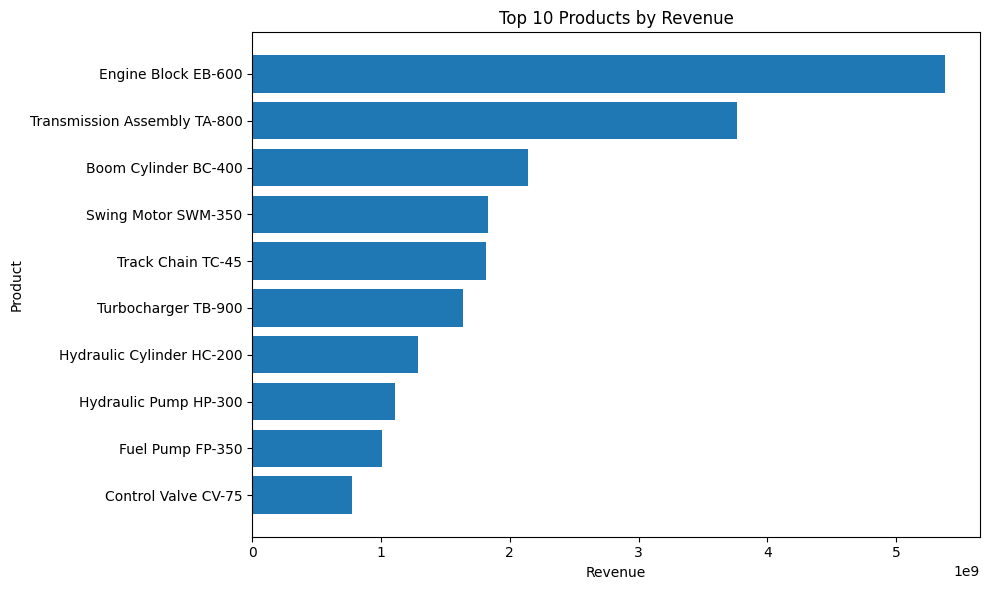

In [7]:
product_group_cols = ["product_id"] + (["product_name"] if "product_name" in data.columns else [])
product_performance = (
    data.groupby(product_group_cols, dropna=False, as_index=False)
        .agg(total_revenue=("line_total", "sum"), total_units=("quantity", "sum"),
             total_orders=("so_id", "nunique"), customers_served=("customer_id", "nunique"),
             branches_served=("branch_id", "nunique"))
)
product_performance["average_revenue_per_order"] = (
    product_performance["total_revenue"] / product_performance["total_orders"].replace(0, np.nan)
)
for source, target in [("total_revenue", "revenue_score"), ("total_units", "unit_score"), ("total_orders", "order_score")]:
    max_value = product_performance[source].max()
    product_performance[target] = product_performance[source] / max_value * 100 if max_value else 0
product_performance["performance_score"] = (
    product_performance["revenue_score"] * 0.50
    + product_performance["unit_score"] * 0.30
    + product_performance["order_score"] * 0.20
)
high_threshold = product_performance["performance_score"].quantile(0.75)
low_threshold = product_performance["performance_score"].quantile(0.25)
product_performance["performance_category"] = np.select(
    [product_performance["performance_score"] >= high_threshold,
     product_performance["performance_score"] <= low_threshold],
    ["High Performance", "Low Performance"], default="Medium Performance"
)
product_performance = product_performance.sort_values("total_revenue", ascending=False)
display(product_performance.head(15))
product_performance.to_csv(TABLE_DIR / "product_performance.csv", index=False)

plot_products = product_performance.head(10).sort_values("total_revenue")
label_col = "product_name" if "product_name" in plot_products.columns else "product_id"
plt.figure(figsize=(10, 6))
plt.barh(plot_products[label_col].astype(str), plot_products["total_revenue"])
plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_products_revenue.png", dpi=150)
plt.show()

### **7. Inventory planning requirements (not current stock)**

In [8]:
inventory_fields = [c for c in ["unit_cost", "safety_stock", "reorder_level", "max_stock_level", "lead_time_days"] if c in data.columns]
if not {"unit_cost", "safety_stock", "reorder_level", "max_stock_level"}.issubset(data.columns):
    print("Some inventory planning fields are unavailable; inventory requirement values will be partially omitted.")

agg = {"units_sold": ("quantity", "sum"), "revenue": ("line_total", "sum")}
for field in inventory_fields:
    agg[field] = (field, "first")
inventory_requirements = data.groupby(product_group_cols, dropna=False, as_index=False).agg(**agg)
if "unit_cost" in inventory_requirements:
    for field, out in [("safety_stock", "safety_stock_value"), ("reorder_level", "reorder_stock_value"), ("max_stock_level", "maximum_stock_value")]:
        if field in inventory_requirements:
            inventory_requirements[out] = inventory_requirements[field] * inventory_requirements["unit_cost"]
display(inventory_requirements.head(15))
inventory_requirements.to_csv(TABLE_DIR / "inventory_planning_requirements.csv", index=False)

value_cols = [c for c in ["safety_stock_value", "reorder_stock_value", "maximum_stock_value"] if c in inventory_requirements]
if value_cols:
    inventory_value_summary = inventory_requirements[value_cols].sum().rename("Total Value").reset_index().rename(columns={"index":"Planning Measure"})
    display(inventory_value_summary)
    inventory_value_summary.to_csv(TABLE_DIR / "inventory_planning_value_summary.csv", index=False)
print("Note: these are stock planning thresholds/values from product master fields, not on-hand inventory or actual stock valuation.")

,product_id,product_name,units_sold,revenue,unit_cost,safety_stock,reorder_level,max_stock_level,lead_time_days,safety_stock_value,reorder_stock_value,maximum_stock_value
0,P001,Hydraulic Pump HP-300,45389,1112030500,18950,10,15,40,21,189500,284250,758000
1,P002,Engine Oil Filter OF-90,45342,32646240,450,40,80,200,7,18000,36000,90000
2,P003,Air Filter AF-120,45684,57105000,820,30,60,150,7,24600,49200,123000
3,P004,Track Chain TC-45,45575,1813885000,32500,4,8,20,30,130000,260000,650000
4,P005,Fuel Injector FI-220,45026,380469700,6350,15,30,80,18,95250,190500,508000
5,P006,Alternator ALT-500,46731,523387200,8650,6,12,30,20,51900,103800,259500
6,P007,Hydraulic Hose HH-60,46468,67378600,980,35,70,200,10,34300,68600,196000
7,P008,Bucket Tooth BT-10,45376,26318080,340,60,120,300,12,20400,40800,102000
8,P009,Starter Motor SM-700,44946,669695400,11450,5,10,25,22,57250,114500,286250
9,P010,Turbocharger TB-900,46964,1639043600,28900,3,6,15,28,86700,173400,433500


,Planning Measure,Total Value
0,safety_stock_value,1924350
1,reorder_stock_value,3623000
2,maximum_stock_value,9915650


Note: these are stock planning thresholds/values from product master fields, not on-hand inventory or actual stock valuation.


### **8. Branch / warehouse-proxy performance**

,branch_id,total_orders,total_units,total_revenue,products_handled,customers_served,average_order_value,revenue_score,order_score,unit_score,product_variety_score,warehouse_score
1,CHN001,4067,280446,5192125100,30,102,1.276647e+06,100.000000,100.000000,100.000000,100.0,100.000000
4,KOL001,3794,256095,4787656160,30,96,1.261902e+06,92.209954,93.287435,91.317045,100.0,93.035102
0,AHM001,3446,236347,4407886140,30,88,1.279131e+06,84.895607,84.730760,84.275404,100.0,86.209784
2,DEL001,2953,204734,3865954470,30,71,1.309162e+06,74.458038,72.608803,73.003002,100.0,76.186166
5,PUN001,2972,201749,3741098180,30,75,1.258781e+06,72.053314,73.075977,71.938626,100.0,75.074976
3,HYD001,2768,189163,3452672510,30,68,1.247353e+06,66.498253,68.059995,67.450775,100.0,70.476994


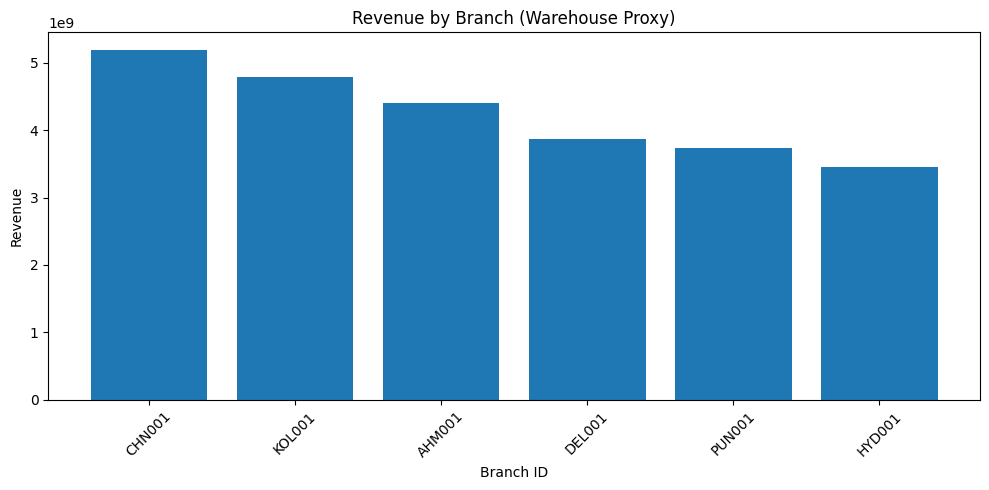

In [9]:
warehouse_performance = (
    data.groupby("branch_id", dropna=False, as_index=False)
        .agg(total_orders=("so_id", "nunique"), total_units=("quantity", "sum"),
             total_revenue=("line_total", "sum"), products_handled=("product_id", "nunique"),
             customers_served=("customer_id", "nunique"))
)
warehouse_performance["average_order_value"] = warehouse_performance["total_revenue"] / warehouse_performance["total_orders"].replace(0, np.nan)
for source, target in [("total_revenue", "revenue_score"), ("total_orders", "order_score"),
                       ("total_units", "unit_score"), ("products_handled", "product_variety_score")]:
    max_value = warehouse_performance[source].max()
    warehouse_performance[target] = warehouse_performance[source] / max_value * 100 if max_value else 0
warehouse_performance["warehouse_score"] = (
    warehouse_performance["revenue_score"] * 0.40
    + warehouse_performance["order_score"] * 0.25
    + warehouse_performance["unit_score"] * 0.25
    + warehouse_performance["product_variety_score"] * 0.10
)
warehouse_performance = warehouse_performance.sort_values("total_revenue", ascending=False)
display(warehouse_performance)
warehouse_performance.to_csv(TABLE_DIR / "branch_warehouse_performance.csv", index=False)

plt.figure(figsize=(10, 5))
plt.bar(warehouse_performance["branch_id"].astype(str), warehouse_performance["total_revenue"])
plt.title("Revenue by Branch (Warehouse Proxy)")
plt.xlabel("Branch ID")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "revenue_by_branch.png", dpi=150)
plt.show()

### **9. Product–branch alignment**

,branch_id,product_id,product_name,total_units,total_revenue,total_orders,customers,branch_revenue_share_pct
44,CHN001,P015,Engine Block EB-600,8869,1055411000,766,102,20.327149
134,KOL001,P015,Engine Block EB-600,8611,1024709000,710,96,21.403145
14,AHM001,P015,Engine Block EB-600,8164,971516000,675,88,22.040406
74,DEL001,P015,Engine Block EB-600,6921,823599000,578,71,21.303898
43,CHN001,P014,Transmission Assembly TA-800,9557,798009500,801,102,15.369612
164,PUN001,P015,Engine Block EB-600,6603,785757000,542,75,21.003378
104,HYD001,P015,Engine Block EB-600,6054,720426000,502,67,20.865750
133,KOL001,P014,Transmission Assembly TA-800,8071,673928500,704,96,14.076376
13,AHM001,P014,Transmission Assembly TA-800,7593,634015500,646,88,14.383663
73,DEL001,P014,Transmission Assembly TA-800,7198,601033000,598,71,15.546820


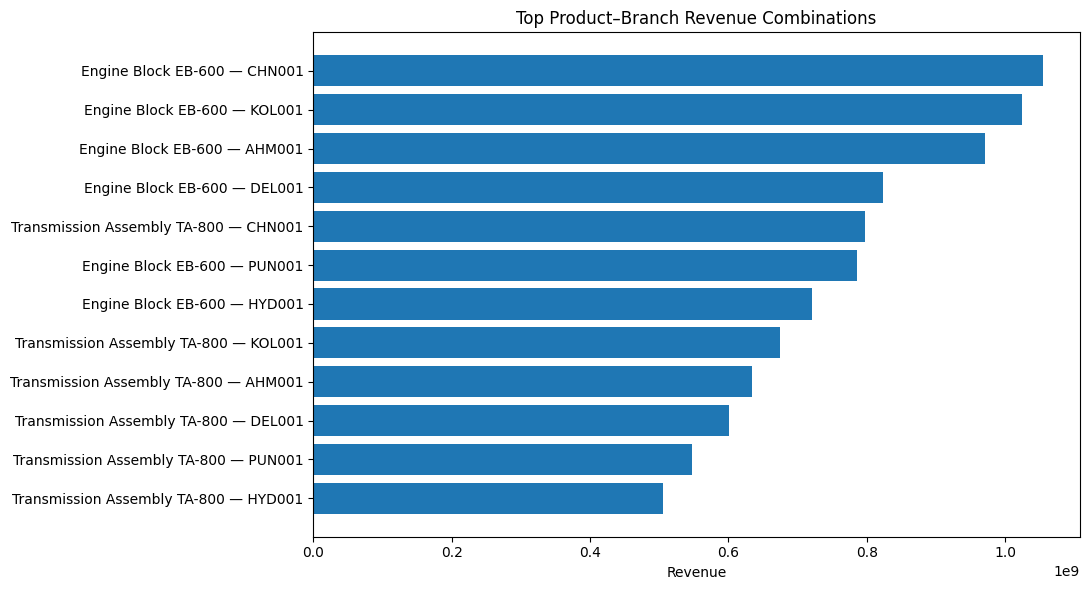

In [10]:
product_warehouse = (
    data.groupby(["branch_id"] + product_group_cols, dropna=False, as_index=False)
        .agg(total_units=("quantity", "sum"), total_revenue=("line_total", "sum"),
             total_orders=("so_id", "nunique"), customers=("customer_id", "nunique"))
)
branch_revenue = product_warehouse.groupby("branch_id")["total_revenue"].transform("sum")
product_warehouse["branch_revenue_share_pct"] = np.where(branch_revenue > 0, product_warehouse["total_revenue"] / branch_revenue * 100, 0)
product_warehouse = product_warehouse.sort_values("total_revenue", ascending=False)
display(product_warehouse.head(20))
product_warehouse.to_csv(TABLE_DIR / "product_branch_alignment.csv", index=False)

# Plot the top 12 product-branch combinations to keep labels readable.
top_combinations = product_warehouse.head(12).copy()
label_product = "product_name" if "product_name" in top_combinations.columns else "product_id"
top_combinations["product_branch_label"] = top_combinations[label_product].astype(str) + " — " + top_combinations["branch_id"].astype(str)
plt.figure(figsize=(11, 6))
plt.barh(top_combinations["product_branch_label"].iloc[::-1], top_combinations["total_revenue"].iloc[::-1])
plt.title("Top Product–Branch Revenue Combinations")
plt.xlabel("Revenue")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "top_product_branch_combinations.png", dpi=150)
plt.show()

### **10. Customer performance and segmentation**

,customer_id,total_revenue,total_units,total_orders,products_purchased,branches_used,average_order_value,customer_segment,customer_status
152,C0153,85877020,4256,59,30,1,1.455543e+06,High Value,Repeat Customer
482,C0483,85183900,3846,53,30,1,1.607243e+06,High Value,Repeat Customer
287,C0288,84094790,4626,63,30,1,1.334838e+06,High Value,Repeat Customer
494,C0495,82914040,3819,52,30,1,1.594501e+06,High Value,Repeat Customer
419,C0420,82700390,4133,54,30,1,1.531489e+06,High Value,Repeat Customer
239,C0240,81776260,3799,50,30,1,1.635525e+06,High Value,Repeat Customer
206,C0207,79795630,3583,51,30,1,1.564620e+06,High Value,Repeat Customer
341,C0342,78469470,3725,44,30,1,1.783397e+06,High Value,Repeat Customer
358,C0359,78412380,3851,52,30,1,1.507930e+06,High Value,Repeat Customer
465,C0466,78342990,3880,52,30,1,1.506596e+06,High Value,Repeat Customer


,customer_segment,customers,total_revenue,average_customer_revenue,average_orders
0,High Value,125,8182742870,65461942.96,46.496
1,Low Value,125,4761449970,38091599.76,34.432
2,Medium Value,250,12503199720,50012798.88,39.536


Repeat customer rate: 100.00%
Interpretation: repeat customer rate is based on customers with more than one distinct order in the available dataset; it is not a cohort-based retention rate.


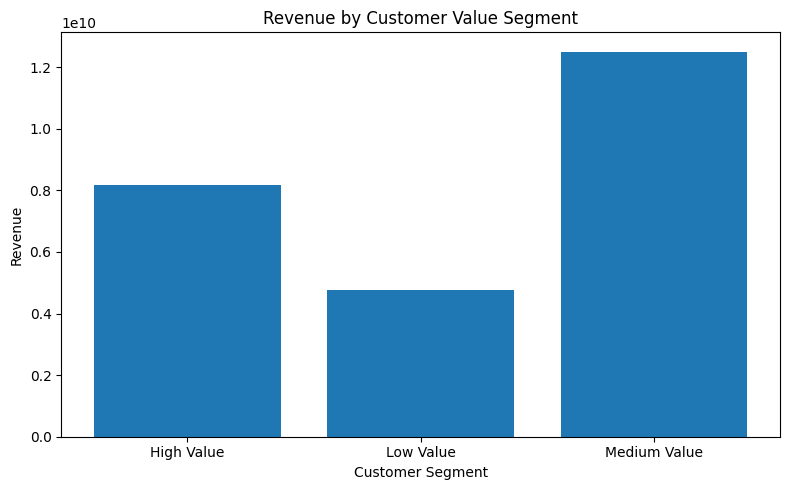

In [11]:
customer_performance = (
    data.groupby("customer_id", dropna=False, as_index=False)
        .agg(total_revenue=("line_total", "sum"), total_units=("quantity", "sum"),
             total_orders=("so_id", "nunique"), products_purchased=("product_id", "nunique"),
             branches_used=("branch_id", "nunique"))
)
customer_performance["average_order_value"] = customer_performance["total_revenue"] / customer_performance["total_orders"].replace(0, np.nan)
high_value_threshold = customer_performance["total_revenue"].quantile(0.75)
low_value_threshold = customer_performance["total_revenue"].quantile(0.25)
customer_performance["customer_segment"] = np.select(
    [customer_performance["total_revenue"] >= high_value_threshold,
     customer_performance["total_revenue"] <= low_value_threshold],
    ["High Value", "Low Value"], default="Medium Value"
)
customer_performance["customer_status"] = np.where(customer_performance["total_orders"] > 1, "Repeat Customer", "One-Time Customer")
repeat_customer_rate = customer_performance["customer_status"].eq("Repeat Customer").mean() * 100 if len(customer_performance) else np.nan

display(customer_performance.sort_values("total_revenue", ascending=False).head(15))
customer_performance.to_csv(TABLE_DIR / "customer_performance.csv", index=False)
segment_summary = customer_performance.groupby("customer_segment", as_index=False).agg(
    customers=("customer_id", "nunique"), total_revenue=("total_revenue", "sum"),
    average_customer_revenue=("total_revenue", "mean"), average_orders=("total_orders", "mean")
)
display(segment_summary)
segment_summary.to_csv(TABLE_DIR / "customer_segment_summary.csv", index=False)
print(f"Repeat customer rate: {repeat_customer_rate:.2f}%" if pd.notna(repeat_customer_rate) else "Repeat customer rate unavailable")
print("Interpretation: repeat customer rate is based on customers with more than one distinct order in the available dataset; it is not a cohort-based retention rate.")

plt.figure(figsize=(8, 5))
plt.bar(segment_summary["customer_segment"], segment_summary["total_revenue"])
plt.title("Revenue by Customer Value Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "revenue_by_customer_segment.png", dpi=150)
plt.show()


### **11. Customer revenue concentration**

,customer_id,total_revenue,revenue_share_pct,cumulative_revenue_share_pct
0,C0153,85877020,0.337469,0.337469
1,C0483,85183900,0.334745,0.672214
2,C0288,84094790,0.330465,1.002679
3,C0495,82914040,0.325825,1.328504
4,C0420,82700390,0.324986,1.653490
5,C0240,81776260,0.321354,1.974844
6,C0207,79795630,0.313571,2.288415
7,C0342,78469470,0.308360,2.596775
8,C0359,78412380,0.308135,2.904910
9,C0466,78342990,0.307863,3.212773


Top 5 customers' revenue share: 1.65%
Top 10 customers' revenue share: 3.21%
Top 20 customers' revenue share: 6.16%


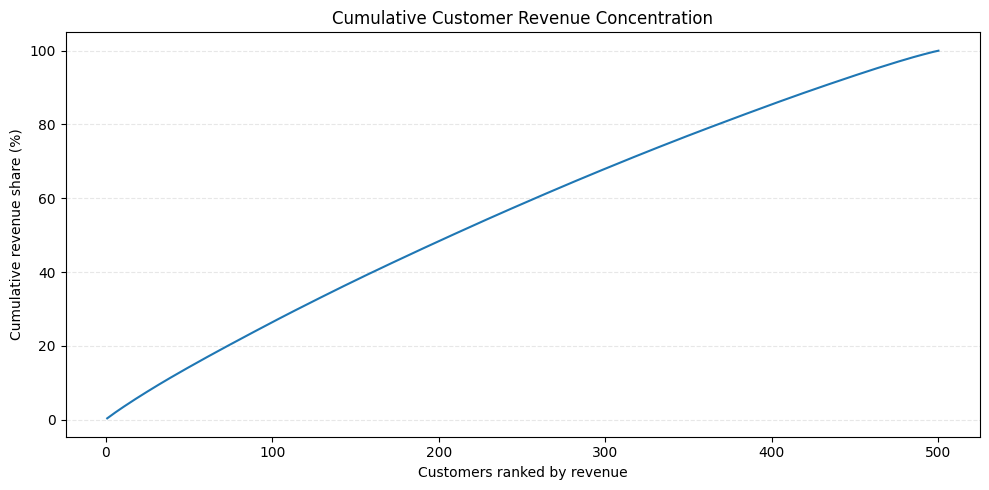

In [12]:
customer_concentration = customer_performance[["customer_id", "total_revenue"]].sort_values("total_revenue", ascending=False).reset_index(drop=True)
total_customer_revenue = customer_concentration["total_revenue"].sum()
customer_concentration["revenue_share_pct"] = np.where(total_customer_revenue > 0, customer_concentration["total_revenue"] / total_customer_revenue * 100, 0)
customer_concentration["cumulative_revenue_share_pct"] = customer_concentration["revenue_share_pct"].cumsum()
display(customer_concentration.head(20))
customer_concentration.to_csv(TABLE_DIR / "customer_revenue_concentration.csv", index=False)

for n in [5, 10, 20]:
    share = customer_concentration.head(n)["revenue_share_pct"].sum()
    print(f"Top {min(n, len(customer_concentration))} customers' revenue share: {share:.2f}%")

plt.figure(figsize=(10, 5))
plt.plot(np.arange(1, len(customer_concentration) + 1), customer_concentration["cumulative_revenue_share_pct"])
plt.title("Cumulative Customer Revenue Concentration")
plt.xlabel("Customers ranked by revenue")
plt.ylabel("Cumulative revenue share (%)")
plt.grid(axis="y", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "customer_revenue_concentration.png", dpi=150)
plt.show()

### **12. Forecast results**

Forecast columns: ['forecast_date', 'forecasted_revenue']


,forecast_date,forecasted_revenue
0,2025-01-31,3.407833e+08
1,2025-02-28,3.215926e+08
2,2025-03-31,3.552769e+08
3,2025-04-30,3.452771e+08
4,2025-05-31,3.500754e+08
5,2025-06-30,3.297413e+08


Forecast horizon: 2025-01-31 00:00:00 to 2025-06-30 00:00:00
Total forecasted revenue across forecast periods: 2042746636.0374198


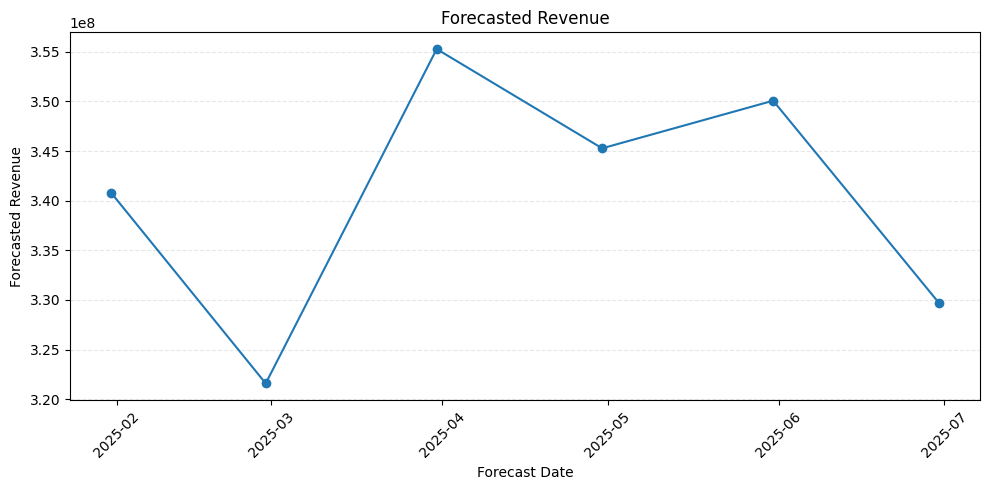

In [13]:
forecast_data = None
if FORECAST_FILE.exists():
    forecast_data = pd.read_csv(FORECAST_FILE)
    print("Forecast columns:", forecast_data.columns.tolist())
    date_candidates = ["forecast_date", "order_date", "date", "ds"]
    revenue_candidates = ["forecasted_revenue", "forecast_revenue", "forecast", "predicted_revenue", "yhat", "revenue"]
    date_col = next((c for c in date_candidates if c in forecast_data.columns), None)
    revenue_col = next((c for c in revenue_candidates if c in forecast_data.columns), None)
    if date_col is None or revenue_col is None:
        print("Forecast file found, but a recognized date or forecast revenue column is missing. Check the column names above.")
        forecast_data = None
    else:
        forecast_data = forecast_data.rename(columns={date_col: "forecast_date", revenue_col: "forecasted_revenue"})
        forecast_data["forecast_date"] = pd.to_datetime(forecast_data["forecast_date"], errors="coerce")
        forecast_data["forecasted_revenue"] = pd.to_numeric(forecast_data["forecasted_revenue"], errors="coerce")
        forecast_data = forecast_data.dropna(subset=["forecast_date", "forecasted_revenue"]).sort_values("forecast_date")
        display(forecast_data)
        forecast_data.to_csv(TABLE_DIR / "forecast_summary.csv", index=False)
        if len(forecast_data):
            print("Forecast horizon:", forecast_data["forecast_date"].min(), "to", forecast_data["forecast_date"].max())
            print("Total forecasted revenue across forecast periods:", forecast_data["forecasted_revenue"].sum())
            plt.figure(figsize=(10, 5))
            plt.plot(forecast_data["forecast_date"], forecast_data["forecasted_revenue"], marker="o")
            plt.title("Forecasted Revenue")
            plt.xlabel("Forecast Date")
            plt.ylabel("Forecasted Revenue")
            plt.xticks(rotation=45)
            plt.grid(axis="y", linestyle="--", alpha=0.3)
            plt.tight_layout()
            plt.savefig(FIGURE_DIR / "forecasted_revenue.png", dpi=150)
            plt.show()
else:
    print(f"Forecast file not found at {FORECAST_FILE}. Forecast analysis skipped; update FORECAST_FILE if it is stored elsewhere.")

### **13. Optional Plotly interactive charts**

In [14]:
if PLOTLY_AVAILABLE:
    fig = px.line(monthly_sales, x="order_date", y="revenue", markers=True,
                  title="Interactive Monthly Revenue Trend")
    fig.show()

    fig = px.bar(product_performance.head(10).sort_values("total_revenue"),
                 x="total_revenue", y=label_col, orientation="h",
                 title="Interactive Top 10 Products by Revenue")
    fig.show()

    fig = px.bar(warehouse_performance, x="branch_id", y="total_revenue",
                 title="Interactive Revenue by Branch")
    fig.show()
else:
    print("Plotly is not installed; matplotlib charts above are available instead.")

### **14. Final integrated KPI summary**

In [15]:
def safe_sum(frame, column):
    return frame[column].sum() if column in frame.columns else np.nan

kpi_rows = [
    ("Total Revenue", total_revenue),
    ("Total Orders", total_orders),
    ("Total Units Sold", total_units),
    ("Total Products", total_products),
    ("Total Customers", total_customers),
    ("Total Branches", total_branches),
    ("Average Order Value", average_order_value),
    ("Repeat Customer Rate (%)", repeat_customer_rate),
    ("Average Product Performance Score", product_performance["performance_score"].mean()),
    ("Average Branch/Warehouse Proxy Score", warehouse_performance["warehouse_score"].mean()),
]
for col, label in [("safety_stock_value", "Safety Stock Planning Value"),
                   ("reorder_stock_value", "Reorder Level Planning Value"),
                   ("maximum_stock_value", "Maximum Stock Planning Value")]:
    if col in inventory_requirements.columns:
        kpi_rows.append((label, safe_sum(inventory_requirements, col)))
if forecast_data is not None and len(forecast_data):
    kpi_rows.append(("Total Forecasted Revenue (all forecast periods)", forecast_data["forecasted_revenue"].sum()))

final_kpis = pd.DataFrame(kpi_rows, columns=["KPI", "Value"])
display(final_kpis)
final_kpis.to_csv(TABLE_DIR / "final_integrated_kpis.csv", index=False)

,KPI,Value
0,Total Revenue,2.544739e+10
1,Total Orders,2.000000e+04
2,Total Units Sold,1.368534e+06
3,Total Products,3.000000e+01
4,Total Customers,5.000000e+02
5,Total Branches,6.000000e+00
6,Average Order Value,1.272370e+06
7,Repeat Customer Rate (%),1.000000e+02
8,Average Product Performance Score,5.633520e+01
9,Average Branch/Warehouse Proxy Score,8.349717e+01


### **15. Export final project tables and figure list**

In [17]:
# Save a concise table inventory to help prepare the Week 12 report
output_inventory = []

for path in sorted(TABLE_DIR.glob("*.csv")):
    output_inventory.append({
        "file": path.name,
        "type": "table",
        "path": str(path)
    })

for path in sorted(FIGURE_DIR.glob("*.png")):
    output_inventory.append({
        "file": path.name,
        "type": "figure",
        "path": str(path)
    })

output_inventory = pd.DataFrame(output_inventory)

display(output_inventory)

# Save the inventory as a CSV file
output_inventory.to_csv(
    OUTPUT_DIR / "output_inventory.csv",
    index=False
)

print("\nFinal outputs saved to:", OUTPUT_DIR)
print("Tables:", TABLE_DIR)
print("Figures:", FIGURE_DIR)

,file,type,path
0,branch_warehouse_performance.csv,table,/content/week12_final_project/tables/branch_wa...
1,customer_performance.csv,table,/content/week12_final_project/tables/customer_...
2,customer_revenue_concentration.csv,table,/content/week12_final_project/tables/customer_...
3,customer_segment_summary.csv,table,/content/week12_final_project/tables/customer_...
4,data_quality_summary.csv,table,/content/week12_final_project/tables/data_qual...
5,executive_kpis.csv,table,/content/week12_final_project/tables/executive...
6,final_integrated_kpis.csv,table,/content/week12_final_project/tables/final_int...
7,forecast_summary.csv,table,/content/week12_final_project/tables/forecast_...
8,inventory_planning_requirements.csv,table,/content/week12_final_project/tables/inventory...
9,inventory_planning_value_summary.csv,table,/content/week12_final_project/tables/inventory...



Final outputs saved to: /content/week12_final_project
Tables: /content/week12_final_project/tables
Figures: /content/week12_final_project/figures
